# 02 – Modélisation

Cible : `available_t30`, nombre de vélos disponibles 30 min plus tard (régression).

## 1. Chargement du fichier

Fichier nettoyé, exporté par `01-exploration.ipynb`.

In [52]:
from pathlib import Path
import pandas as pd

path = Path("raw/data/historique_nettoye.csv")

In [53]:
df = pd.read_csv(path, dtype={"station_code": "str"}, parse_dates=["horodatage"])
df.shape

(2795162, 25)

In [54]:
df.head()

,horodatage,station_code,capacity,velo_meca,velo_elec,station_name,operative,latitude,longitude,available,...,heure_cos,is_weekend,heure,delta_abs,is_rush_hour,temperature_2m,wind_speed_10m,precipitation,rain,weather_label
0,2026-10-16 13:50:00+00:00,1001,17,7,7,Quai de l'Horloge - Pont Neuf,True,48.85706,2.3418,14,...,-0.887011,False,15,7,False,21.39,12.75,0.0,0.0,Overcast
1,2026-10-16 13:55:00+00:00,1001,17,7,6,Quai de l'Horloge - Pont Neuf,True,48.85706,2.3418,13,...,-0.876727,False,15,6,False,21.35,12.64,0.0,0.0,Overcast
2,2026-10-16 14:05:00+00:00,1001,17,7,6,Quai de l'Horloge - Pont Neuf,True,48.85706,2.3418,13,...,-0.854912,False,16,1,True,21.29,12.34,0.0,0.0,Overcast
3,2026-10-16 14:10:00+00:00,1001,17,7,6,Quai de l'Horloge - Pont Neuf,True,48.85706,2.3418,13,...,-0.843391,False,16,1,True,21.25,12.15,0.0,0.0,Overcast
4,2026-10-16 14:15:00+00:00,1001,17,7,6,Quai de l'Horloge - Pont Neuf,True,48.85706,2.3418,13,...,-0.831470,False,16,1,True,21.22,11.97,0.0,0.0,Overcast


## Features supplémentaires

Chaque feature n'utilise que des informations connues à l'instant t (le présent, le passé, ou l'état des autres stations au même instant), donc il n'y a pas de fuite vers le futur.

### Remplissage de la station

In [55]:
df["taux_remplissage"] = df["available"] / df["capacity"]
df["station_vide"] = (df["available"] == 0).astype(int)
df["station_pleine"] = (df["available"] >= df["capacity"]).astype(int)

### Même heure la veille

Nombre de vélos 24 heures plus tôt (vide si le relevé de la veille n'existe pas).

In [56]:
veille = df[["horodatage", "station_code", "available"]].copy()
veille["horodatage"] = veille["horodatage"] + pd.Timedelta(days=1)
veille = veille.rename(columns={"available": "available_veille"})

df = df.merge(veille, on=["horodatage", "station_code"], how="left")
df["ecart_veille"] = df["available"] - df["available_veille"]

### Stations voisines

Deux stations sont voisines si elles sont à moins de 500 m. Pour chaque station et chaque instant, on calcule la moyenne de leurs voisines au même instant : taux de remplissage et variation des 30 dernières minutes.

In [57]:
import numpy as np

stations = df.groupby("station_code")[["latitude", "longitude"]].first()
lat = np.radians(stations["latitude"].to_numpy())
lon = np.radians(stations["longitude"].to_numpy())

In [116]:
# distance en mètres entre chaque paire de stations (formule de haversine)
a = (
    np.sin((lat[:, None] - lat[None, :]) / 2) ** 2
    + np.cos(lat[:, None]) * np.cos(lat[None, :]) * np.sin((lon[:, None] - lon[None, :]) / 2) ** 2
)
distance_m = 2 * 6371000 * np.arcsin(np.sqrt(a))

In [117]:
voisines = distance_m <= 500
np.fill_diagonal(voisines, False)  # une station n'est pas sa propre voisine
nb_voisines = pd.Series(voisines.sum(axis=1), index=stations.index, name="nb_voisines")
nb_voisines.describe()

count    1215.000000
mean        7.924280
std         4.593799
min         0.000000
25%         5.000000
50%         8.000000
75%        10.000000
max        22.000000
Name: nb_voisines, dtype: float64

Une ligne par instant, une colonne par station.

In [60]:
taux = df.pivot(index="horodatage", columns="station_code", values="taux_remplissage")[stations.index]
variation = df.pivot(index="horodatage", columns="station_code", values="delta_t30")[stations.index]

Moyenne des voisines, en ignorant celles dont la valeur manque à cet instant.

In [61]:
def moyenne_voisines(tableau):
    valeurs = tableau.to_numpy(dtype=float)
    presentes = (~np.isnan(valeurs)).astype(float)
    somme = np.where(presentes, valeurs, 0) @ voisines.T.astype(float)
    nombre = presentes @ voisines.T.astype(float)
    with np.errstate(invalid="ignore", divide="ignore"):
        moyenne = somme / nombre
    return pd.DataFrame(moyenne, index=tableau.index, columns=tableau.columns)

In [62]:
voisines_taux = moyenne_voisines(taux).stack().rename("voisines_taux")
voisines_variation = moyenne_voisines(variation).stack().rename("voisines_variation")

In [63]:
df = df.merge(voisines_taux.reset_index(), on=["horodatage", "station_code"], how="left")
df = df.merge(voisines_variation.reset_index(), on=["horodatage", "station_code"], how="left")
df = df.merge(nb_voisines.reset_index(), on="station_code", how="left")
df[["voisines_taux", "voisines_variation", "nb_voisines"]].describe()

,voisines_taux,voisines_variation,nb_voisines
count,2.707686e+06,2.707686e+06,2.795162e+06
mean,3.586170e-01,-4.055857e-03,7.919313e+00
std,2.225834e-01,1.063657e+00,4.588177e+00
min,0.000000e+00,-2.533333e+01,0.000000e+00
25%,1.788564e-01,-4.285714e-01,5.000000e+00
50%,3.190645e-01,0.000000e+00,8.000000e+00
75%,5.093750e-01,4.000000e-01,1.000000e+01
max,1.190611e+00,3.000000e+01,2.200000e+01


## 2. Découpage train / test

Les 2 derniers jours du jeu nettoyé forment le jeu de test : on n'y touche pas avant l'évaluation finale. Le reste constitue le jeu d'entraînement, sur lequel la validation et le réglage des modèles se font.

In [64]:
# format 17-10-2026 18:30
horodatage = df["horodatage"].astype(str).str.replace(
    r"(\d{4})-(\d{2})-(\d{2}) (\d{2}):(\d{2}).*", r"\3-\2-\1 \4:\5", regex=True
)
df["horodatage"] = pd.to_datetime(horodatage, format="%d-%m-%Y %H:%M")

debut_test = pd.to_datetime("24-10-2026 00:00", format="%d-%m-%Y %H:%M")

In [65]:
test = df[df["horodatage"] >= debut_test]
train = df[df["horodatage"] < debut_test]
print(train.shape, test.shape)


(2194232, 33) (600930, 33)


In [66]:
ratio = train.shape[0] / df.shape[0]
print(ratio)

0.7850106720111393


## 3. Plis d'entraînement

On travaille uniquement dans `train`. Chaque pli teste sur un jour et s'entraîne sur tous les jours d'avant :

- pli 1 : entraînement du 16 au 17, validation le 18
- pli 2 : entraînement du 16 au 18, validation le 19
- et ainsi de suite jusqu'au pli 6 (validation le 23)

Le 16 et le 17 sont des journées incomplètes (début de la collecte, relevés irréguliers) mais on les garde pour l'entraînement. On retire 30 minutes à la fin de l'entraînement : la cible d'une ligne est observée 30 minutes plus tard, elle ne doit pas tomber dans le jour de validation.

In [67]:
purge = pd.Timedelta(minutes=30)

In [68]:
j16 = pd.to_datetime("16-10-2026 00:00", format="%d-%m-%Y %H:%M")
j17 = pd.to_datetime("17-10-2026 00:00", format="%d-%m-%Y %H:%M")

In [69]:
j18 = pd.to_datetime("18-10-2026 00:00", format="%d-%m-%Y %H:%M")

In [70]:
j19 = pd.to_datetime("19-10-2026 00:00", format="%d-%m-%Y %H:%M")

In [71]:
j20 = pd.to_datetime("20-10-2026 00:00", format="%d-%m-%Y %H:%M")

In [72]:
j21 = pd.to_datetime("21-10-2026 00:00", format="%d-%m-%Y %H:%M")

In [73]:
j22 = pd.to_datetime("22-10-2026 00:00", format="%d-%m-%Y %H:%M")

In [74]:
j23 = pd.to_datetime("23-10-2026 00:00", format="%d-%m-%Y %H:%M")

In [75]:
j24 = pd.to_datetime("24-10-2026 00:00", format="%d-%m-%Y %H:%M")

### Pli 1

In [76]:
train_1 = train[(train["horodatage"] >= j16) & (train["horodatage"] < j18 - purge)]
val_1 = train[(train["horodatage"] >= j18) & (train["horodatage"] < j19)]
print(train_1.shape, val_1.shape)

(125145, 33) (345060, 33)


### Pli 2

In [77]:
train_2 = train[(train["horodatage"] >= j16) & (train["horodatage"] < j19 - purge)]
val_2 = train[(train["horodatage"] >= j19) & (train["horodatage"] < j20)]
print(train_2.shape, val_2.shape)

(464130, 33) (342630, 33)


### Pli 3

In [78]:
train_3 = train[(train["horodatage"] >= j16) & (train["horodatage"] < j20 - purge)]
val_3 = train[(train["horodatage"] >= j20) & (train["horodatage"] < j21)]
print(train_3.shape, val_3.shape)

(805545, 33) (348337, 33)


### Pli 4

In [79]:
train_4 = train[(train["horodatage"] >= j16) & (train["horodatage"] < j21 - purge)]
val_4 = train[(train["horodatage"] >= j21) & (train["horodatage"] < j22)]
print(train_4.shape, val_4.shape)

(1155107, 33) (347070, 33)


### Pli 5

In [80]:
train_5 = train[(train["horodatage"] >= j16) & (train["horodatage"] < j22 - purge)]
val_5 = train[(train["horodatage"] >= j22) & (train["horodatage"] < j23)]
print(train_5.shape, val_5.shape)

(1500952, 33) (336358, 33)


### Pli 6

In [81]:
train_6 = train[(train["horodatage"] >= j16) & (train["horodatage"] < j23 - purge)]
val_6 = train[(train["horodatage"] >= j23) & (train["horodatage"] < j24)]
print(train_6.shape, val_6.shape)

(1838530, 33) (349632, 33)


## 4. La variation du passé aide-t-elle à prédire le futur ?

`delta_t30` est la variation des 30 dernières minutes (`available - available_last_30`). On la compare à la variation des 30 prochaines minutes, calculée sur `train` uniquement.

In [82]:
futur = train["available_t30"] - train["available"]

Corrélation de Pearson entre la variation du passé et la variation du futur.

In [83]:
train["delta_t30"].corr(futur)

np.float64(0.10325949021823)

Corrélation de Spearman (sur les rangs, moins sensible aux valeurs extrêmes).

In [84]:
train["delta_t30"].corr(futur, method="spearman")

np.float64(0.025991624622658083)

Corrélation avec la cible `available_t30` elle-même.

In [85]:
train["delta_t30"].corr(train["available_t30"])

np.float64(0.10639194324454394)

Variation moyenne du futur selon l'ampleur de la variation du passé.

In [86]:
tranches = pd.cut(train["delta_t30"], [-float("inf"), -5, -2, -1, 0, 1, 2, 5, float("inf")])
futur.groupby(tranches, observed=True).agg(["size", "mean"])

,size,mean
delta_t30,,
"(-inf, -5.0]",53717,-1.064002
"(-5.0, -2.0]",289099,-0.128257
"(-2.0, -1.0]",336539,0.010026
"(-1.0, 0.0]",842956,0.020152
"(0.0, 1.0]",335954,0.008031
"(1.0, 2.0]",160835,0.021457
"(2.0, 5.0]",143227,0.177027
"(5.0, inf]",31905,1.352108


## 5. Baseline : la persistance

Prédiction sans modèle : dans 30 minutes, il y aura autant de vélos qu'à l'instant présent, donc `prédiction = available`.

- erreur = prédiction - vraie valeur (`available_t30`)
- MAE = moyenne de la valeur absolue de l'erreur
- RMSE = racine de la moyenne de l'erreur au carré

On calcule les deux sur chaque jour de validation.

### Pli 1

In [87]:
erreur = val_1["available"] - val_1["available_t30"]
mae_1 = erreur.abs().mean()
rmse_1 = (erreur ** 2).mean() ** 0.5
print("MAE1 :", round(mae_1, 3), "| RMSE1 :", round(rmse_1, 3))

MAE1 : 1.233 | RMSE1 : 2.036


### Pli 2

In [88]:
erreur = val_2["available"] - val_2["available_t30"]
mae_2 = erreur.abs().mean()
rmse_2 = (erreur ** 2).mean() ** 0.5
print("MAE2 :", round(mae_2, 3), "| RMSE2 :", round(rmse_2, 3))

MAE2 : 1.282 | RMSE2 : 2.19


### Pli 3

In [89]:
erreur = val_3["available"] - val_3["available_t30"]
mae_3 = erreur.abs().mean()
rmse_3 = (erreur ** 2).mean() ** 0.5
print("MAE3 :", round(mae_3, 3), "| RMSE3 :", round(rmse_3, 3))

MAE3 : 1.344 | RMSE3 : 2.27


### Pli 4

In [90]:
erreur = val_4["available"] - val_4["available_t30"]
mae_4 = erreur.abs().mean()
rmse_4 = (erreur ** 2).mean() ** 0.5
print("MAE4 :", round(mae_4, 3), "| RMSE4 :", round(rmse_4, 3))

MAE4 : 1.352 | RMSE4 : 2.299


### Pli 5

In [91]:
erreur = val_5["available"] - val_5["available_t30"]
mae_5 = erreur.abs().mean()
rmse_5 = (erreur ** 2).mean() ** 0.5
print("MAE5 :", round(mae_5, 3), "| RMSE5 :", round(rmse_5, 3))

MAE5 : 1.367 | RMSE5 : 2.316


### Pli 6

In [92]:
erreur = val_6["available"] - val_6["available_t30"]
mae_6 = erreur.abs().mean()
rmse_6 = (erreur ** 2).mean() ** 0.5
print("MAE6 :", round(mae_6, 3), "| RMSE6 :", round(rmse_6, 3))

MAE6 : 1.111 | RMSE6 : 1.883


### Moyenne sur les 6 plis

In [93]:
print("MAE moyenne :", round((mae_1 + mae_2 + mae_3 + mae_4 + mae_5 + mae_6) / 6, 3))
print("RMSE moyenne :", round((rmse_1 + rmse_2 + rmse_3 + rmse_4 + rmse_5 + rmse_6) / 6, 3))

MAE moyenne : 1.281
RMSE moyenne : 2.166


## 6. Matrice de corrélation

Calculée sur `train` uniquement. Rouge : les deux variables montent ensemble. Bleu : quand l'une monte, l'autre descend. Blanc : pas de lien linéaire.

`delta_futur` est la variation des 30 prochaines minutes (`available_t30 - available`), c'est ce qu'on cherche à prédire.

In [94]:
train = train.assign(delta_futur=train["available_t30"] - train["available"])

In [95]:
colonnes = [
    "available", "available_last_30", "delta_t30", "delta_abs",
    "capacity", "velo_meca", "velo_elec", "latitude", "longitude",
    "heure_sin", "heure_cos", "is_weekend", "is_rush_hour",
    "temperature_2m", "wind_speed_10m", "precipitation", "rain",
    "available_t30", "delta_futur",
]

In [96]:
corr = train[colonnes].astype(float).corr()

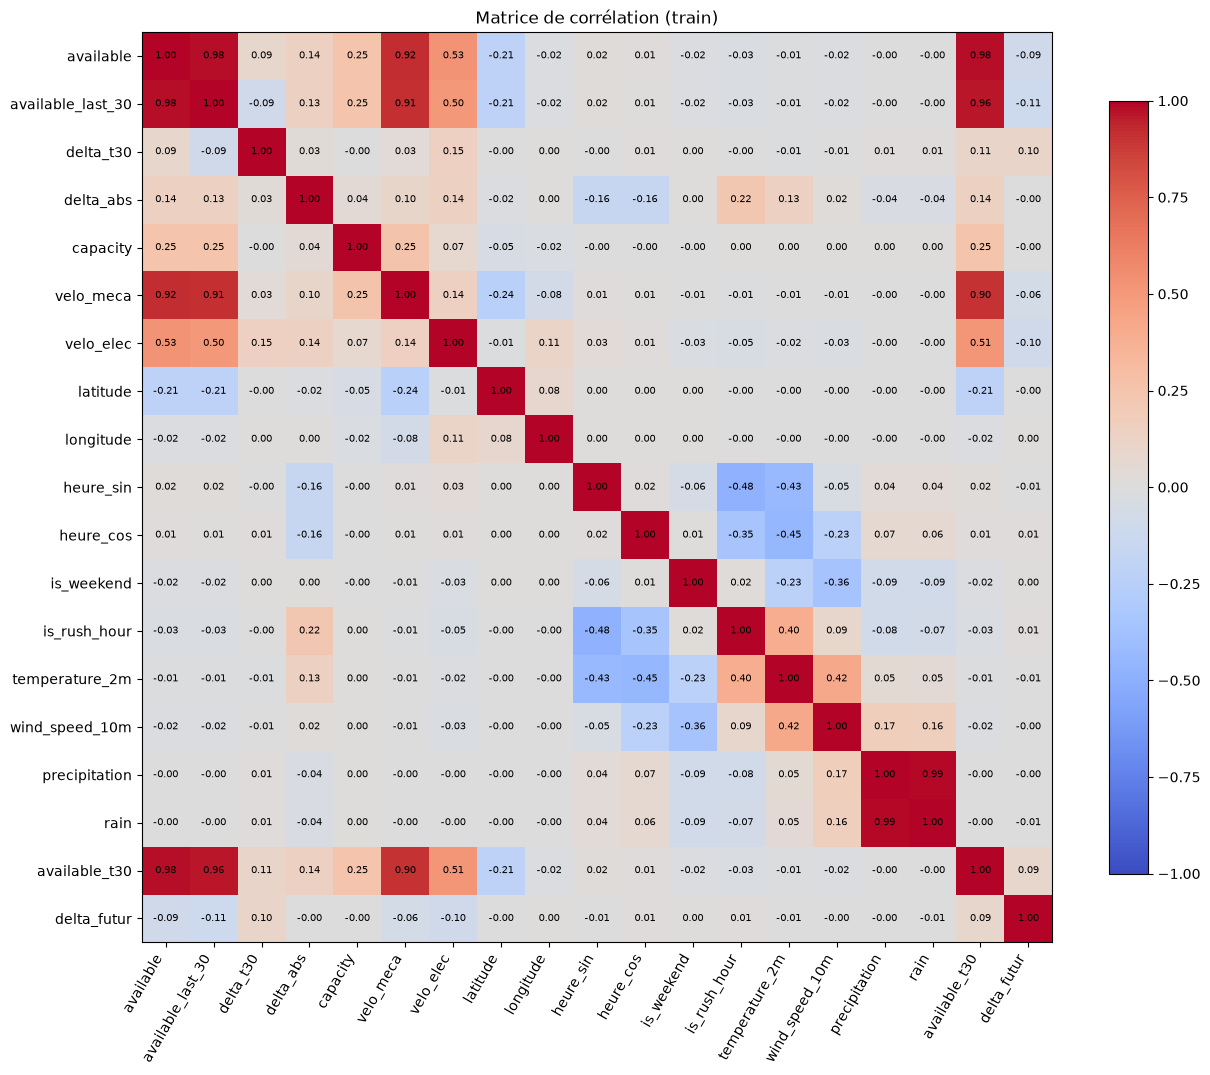

In [97]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(13, 11))
image = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)

ax.set_xticks(range(len(colonnes)), colonnes, rotation=60, ha="right")
ax.set_yticks(range(len(colonnes)), colonnes)

for i in range(len(colonnes)):
    for j in range(len(colonnes)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)

fig.colorbar(image, ax=ax, shrink=0.8)
ax.set_title("Matrice de corrélation (train)")
plt.tight_layout()
plt.show()

Corrélation de chaque variable avec `delta_futur`, de la plus négative à la plus positive.

In [98]:
corr["delta_futur"].drop("delta_futur").sort_values()

available_last_30   -0.112623
velo_elec           -0.099139
available           -0.093913
velo_meca           -0.062552
heure_sin           -0.007523
temperature_2m      -0.006177
rain                -0.005220
precipitation       -0.004904
wind_speed_10m      -0.004497
delta_abs           -0.004237
latitude            -0.001304
capacity            -0.001021
longitude            0.001486
is_weekend           0.004948
is_rush_hour         0.013353
heure_cos            0.013413
available_t30        0.088222
delta_t30            0.103259
Name: delta_futur, dtype: float64

## 7. XGBoost

Le modèle prédit la variation du futur (`available_t30 - available`). La prédiction finale est `available` plus cette variation, arrondie à l'entier puis bornée entre 0 et la capacité de la station.

Perte `reg:absoluteerror` : elle vise la MAE, la métrique qu'on essaie de battre.

In [99]:
from xgboost import XGBRegressor

In [100]:
features = [
    "available", "available_last_30", "delta_t30", "velo_elec", "velo_meca",
    "capacity", "latitude", "longitude", "heure_sin", "heure_cos",
    "is_weekend", "is_rush_hour", "temperature_2m", "wind_speed_10m", "precipitation",
]

### Pli 1

In [101]:
modele_1 = XGBRegressor(objective="reg:absoluteerror", n_estimators=200, max_depth=6, learning_rate=0.1)
modele_1.fit(train_1[features], train_1["available_t30"] - train_1["available"])

delta_pred = modele_1.predict(val_1[features]).round()
prediction = (val_1["available"] + delta_pred).clip(0, val_1["capacity"])

erreur = prediction - val_1["available_t30"]
mae_xgb_1 = erreur.abs().mean()
rmse_xgb_1 = (erreur ** 2).mean() ** 0.5
print("MAE1 xgb :", round(mae_xgb_1, 3), "| RMSE1 xgb :", round(rmse_xgb_1, 3))

MAE1 xgb : 1.344 | RMSE1 xgb : 2.127


### Pli 2

In [102]:
modele_2 = XGBRegressor(objective="reg:absoluteerror", n_estimators=200, max_depth=6, learning_rate=0.1)
modele_2.fit(train_2[features], train_2["available_t30"] - train_2["available"])

delta_pred = modele_2.predict(val_2[features]).round()
prediction = (val_2["available"] + delta_pred).clip(0, val_2["capacity"])

erreur = prediction - val_2["available_t30"]
mae_xgb_2 = erreur.abs().mean()
rmse_xgb_2 = (erreur ** 2).mean() ** 0.5
print("MAE2 xgb :", round(mae_xgb_2, 3), "| RMSE2 xgb :", round(rmse_xgb_2, 3))

MAE2 xgb : 1.312 | RMSE2 xgb : 2.254


### Pli 3

In [103]:
modele_3 = XGBRegressor(objective="reg:absoluteerror", n_estimators=200, max_depth=6, learning_rate=0.1)
modele_3.fit(train_3[features], train_3["available_t30"] - train_3["available"])

delta_pred = modele_3.predict(val_3[features]).round()
prediction = (val_3["available"] + delta_pred).clip(0, val_3["capacity"])

erreur = prediction - val_3["available_t30"]
mae_xgb_3 = erreur.abs().mean()
rmse_xgb_3 = (erreur ** 2).mean() ** 0.5
print("MAE3 xgb :", round(mae_xgb_3, 3), "| RMSE3 xgb :", round(rmse_xgb_3, 3))

MAE3 xgb : 1.344 | RMSE3 xgb : 2.339


### Pli 4

In [104]:
modele_4 = XGBRegressor(objective="reg:absoluteerror", n_estimators=200, max_depth=6, learning_rate=0.1)
modele_4.fit(train_4[features], train_4["available_t30"] - train_4["available"])

delta_pred = modele_4.predict(val_4[features]).round()
prediction = (val_4["available"] + delta_pred).clip(0, val_4["capacity"])

erreur = prediction - val_4["available_t30"]
mae_xgb_4 = erreur.abs().mean()
rmse_xgb_4 = (erreur ** 2).mean() ** 0.5
print("MAE4 xgb :", round(mae_xgb_4, 3), "| RMSE4 xgb :", round(rmse_xgb_4, 3))

MAE4 xgb : 1.324 | RMSE4 xgb : 2.251


### Pli 5

In [105]:
modele_5 = XGBRegressor(objective="reg:absoluteerror", n_estimators=200, max_depth=6, learning_rate=0.1)
modele_5.fit(train_5[features], train_5["available_t30"] - train_5["available"])

delta_pred = modele_5.predict(val_5[features]).round()
prediction = (val_5["available"] + delta_pred).clip(0, val_5["capacity"])

erreur = prediction - val_5["available_t30"]
mae_xgb_5 = erreur.abs().mean()
rmse_xgb_5 = (erreur ** 2).mean() ** 0.5
print("MAE5 xgb :", round(mae_xgb_5, 3), "| RMSE5 xgb :", round(rmse_xgb_5, 3))

MAE5 xgb : 1.323 | RMSE5 xgb : 2.222


### Pli 6

In [106]:
modele_6 = XGBRegressor(objective="reg:absoluteerror", n_estimators=200, max_depth=6, learning_rate=0.1)
modele_6.fit(train_6[features], train_6["available_t30"] - train_6["available"])

delta_pred = modele_6.predict(val_6[features]).round()
prediction = (val_6["available"] + delta_pred).clip(0, val_6["capacity"])

erreur = prediction - val_6["available_t30"]
mae_xgb_6 = erreur.abs().mean()
rmse_xgb_6 = (erreur ** 2).mean() ** 0.5
print("MAE6 xgb :", round(mae_xgb_6, 3), "| RMSE6 xgb :", round(rmse_xgb_6, 3))

MAE6 xgb : 1.125 | RMSE6 xgb : 1.872


### Moyenne sur les 6 plis, comparée à la persistance

In [107]:
print("MAE moyenne xgb :", round((mae_xgb_1 + mae_xgb_2 + mae_xgb_3 + mae_xgb_4 + mae_xgb_5 + mae_xgb_6) / 6, 3))
print("RMSE moyenne xgb :", round((rmse_xgb_1 + rmse_xgb_2 + rmse_xgb_3 + rmse_xgb_4 + rmse_xgb_5 + rmse_xgb_6) / 6, 3))
print("MAE moyenne persistance :", round((mae_1 + mae_2 + mae_3 + mae_4 + mae_5 + mae_6) / 6, 3))
print("RMSE moyenne persistance :", round((rmse_1 + rmse_2 + rmse_3 + rmse_4 + rmse_5 + rmse_6) / 6, 3))

MAE moyenne xgb : 1.295
RMSE moyenne xgb : 2.177
MAE moyenne persistance : 1.281
RMSE moyenne persistance : 2.166


## 8. XGBoost avec les stations voisines

Même modèle que la section 7, avec en plus l'état des stations voisines (moins de 500 m) au même instant : leur taux de remplissage moyen, leur variation moyenne sur les 30 dernières minutes, et leur nombre.

In [108]:
features_voisines = features + ["voisines_taux", "voisines_variation", "nb_voisines"]

### Pli 1

In [109]:
modele_1 = XGBRegressor(objective="reg:absoluteerror", n_estimators=200, max_depth=6, learning_rate=0.1)
modele_1.fit(train_1[features_voisines], train_1["available_t30"] - train_1["available"])

delta_pred = modele_1.predict(val_1[features_voisines]).round()
prediction = (val_1["available"] + delta_pred).clip(0, val_1["capacity"])

erreur = prediction - val_1["available_t30"]
mae_vois_1 = erreur.abs().mean()
rmse_vois_1 = (erreur ** 2).mean() ** 0.5
print("MAE1 voisines :", round(mae_vois_1, 3), "| RMSE1 voisines :", round(rmse_vois_1, 3))

MAE1 voisines : 1.325 | RMSE1 voisines : 2.097


### Pli 2

In [110]:
modele_2 = XGBRegressor(objective="reg:absoluteerror", n_estimators=200, max_depth=6, learning_rate=0.1)
modele_2.fit(train_2[features_voisines], train_2["available_t30"] - train_2["available"])

delta_pred = modele_2.predict(val_2[features_voisines]).round()
prediction = (val_2["available"] + delta_pred).clip(0, val_2["capacity"])

erreur = prediction - val_2["available_t30"]
mae_vois_2 = erreur.abs().mean()
rmse_vois_2 = (erreur ** 2).mean() ** 0.5
print("MAE2 voisines :", round(mae_vois_2, 3), "| RMSE2 voisines :", round(rmse_vois_2, 3))

MAE2 voisines : 1.29 | RMSE2 voisines : 2.22


### Pli 3

In [111]:
modele_3 = XGBRegressor(objective="reg:absoluteerror", n_estimators=200, max_depth=6, learning_rate=0.1)
modele_3.fit(train_3[features_voisines], train_3["available_t30"] - train_3["available"])

delta_pred = modele_3.predict(val_3[features_voisines]).round()
prediction = (val_3["available"] + delta_pred).clip(0, val_3["capacity"])

erreur = prediction - val_3["available_t30"]
mae_vois_3 = erreur.abs().mean()
rmse_vois_3 = (erreur ** 2).mean() ** 0.5
print("MAE3 voisines :", round(mae_vois_3, 3), "| RMSE3 voisines :", round(rmse_vois_3, 3))

MAE3 voisines : 1.319 | RMSE3 voisines : 2.295


### Pli 4

In [112]:
modele_4 = XGBRegressor(objective="reg:absoluteerror", n_estimators=200, max_depth=6, learning_rate=0.1)
modele_4.fit(train_4[features_voisines], train_4["available_t30"] - train_4["available"])

delta_pred = modele_4.predict(val_4[features_voisines]).round()
prediction = (val_4["available"] + delta_pred).clip(0, val_4["capacity"])

erreur = prediction - val_4["available_t30"]
mae_vois_4 = erreur.abs().mean()
rmse_vois_4 = (erreur ** 2).mean() ** 0.5
print("MAE4 voisines :", round(mae_vois_4, 3), "| RMSE4 voisines :", round(rmse_vois_4, 3))

MAE4 voisines : 1.303 | RMSE4 voisines : 2.211


### Pli 5

In [113]:
modele_5 = XGBRegressor(objective="reg:absoluteerror", n_estimators=200, max_depth=6, learning_rate=0.1)
modele_5.fit(train_5[features_voisines], train_5["available_t30"] - train_5["available"])

delta_pred = modele_5.predict(val_5[features_voisines]).round()
prediction = (val_5["available"] + delta_pred).clip(0, val_5["capacity"])

erreur = prediction - val_5["available_t30"]
mae_vois_5 = erreur.abs().mean()
rmse_vois_5 = (erreur ** 2).mean() ** 0.5
print("MAE5 voisines :", round(mae_vois_5, 3), "| RMSE5 voisines :", round(rmse_vois_5, 3))

MAE5 voisines : 1.304 | RMSE5 voisines : 2.188


### Pli 6

In [114]:
modele_6 = XGBRegressor(objective="reg:absoluteerror", n_estimators=200, max_depth=6, learning_rate=0.1)
modele_6.fit(train_6[features_voisines], train_6["available_t30"] - train_6["available"])

delta_pred = modele_6.predict(val_6[features_voisines]).round()
prediction = (val_6["available"] + delta_pred).clip(0, val_6["capacity"])

erreur = prediction - val_6["available_t30"]
mae_vois_6 = erreur.abs().mean()
rmse_vois_6 = (erreur ** 2).mean() ** 0.5
print("MAE6 voisines :", round(mae_vois_6, 3), "| RMSE6 voisines :", round(rmse_vois_6, 3))

MAE6 voisines : 1.116 | RMSE6 voisines : 1.857


### Comparaison des trois approches (moyenne sur les 6 plis)

In [115]:
comparaison = pd.DataFrame({
    "MAE": [
        (mae_1 + mae_2 + mae_3 + mae_4 + mae_5 + mae_6) / 6,
        (mae_xgb_1 + mae_xgb_2 + mae_xgb_3 + mae_xgb_4 + mae_xgb_5 + mae_xgb_6) / 6,
        (mae_vois_1 + mae_vois_2 + mae_vois_3 + mae_vois_4 + mae_vois_5 + mae_vois_6) / 6,
    ],
    "RMSE": [
        (rmse_1 + rmse_2 + rmse_3 + rmse_4 + rmse_5 + rmse_6) / 6,
        (rmse_xgb_1 + rmse_xgb_2 + rmse_xgb_3 + rmse_xgb_4 + rmse_xgb_5 + rmse_xgb_6) / 6,
        (rmse_vois_1 + rmse_vois_2 + rmse_vois_3 + rmse_vois_4 + rmse_vois_5 + rmse_vois_6) / 6,
    ],
}, index=["persistance", "xgboost", "xgboost + voisines"])
comparaison.round(3)

,MAE,RMSE
persistance,1.281,2.166
xgboost,1.295,2.177
xgboost + voisines,1.276,2.145
